# Task 3 — Transactional Database Construction

Notebook ini membangun dan menganalisis dua representasi *transactional database* dari dataset DBLP 2015–2025 hasil preprocessing:
1. **Author-Based Transaction**: 1 transaksi = 1 author, item = daftar unik konferensi/workshop tempat author pernah memublikasikan paper sepanjang 2015–2025.
2. **Author-Year-Based Transaction**: 1 transaksi = kombinasi `(author, year)`, item = daftar unik konferensi/workshop tempat author memublikasikan paper pada tahun tersebut.


In [1]:
import os
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.plotting import PALETTE, apply_publication_style, clean_axes, save_figure

apply_publication_style(base_font_size=11)
os.makedirs("../outputs/figures", exist_ok=True)
os.makedirs("../tables", exist_ok=True)

tx_author = pd.read_parquet("../data/processed/tx_author_based.parquet")
tx_ay = pd.read_parquet("../data/processed/tx_author_year_based.parquet")
summary_df = pd.read_csv("../tables/task3_transaction_summary.csv")
dist_df = pd.read_csv("../tables/task3_item_count_distribution.csv")
sample_author = pd.read_csv("../tables/task3_sample_author_tx.csv")
sample_ay = pd.read_csv("../tables/task3_sample_author_year_tx.csv")

print(f"Author-Based transactions     : {len(tx_author):,}")
print(f"Author-Year-Based transactions: {len(tx_ay):,}")


Author-Based transactions     : 1,822,489
Author-Year-Based transactions: 4,088,557


## 1. Contoh Transaksi (Minimal 10 Contoh per Representasi)


In [2]:
print("=== 15 Contoh Author-Based Transactions ===")
display(sample_author)

print("\n=== 15 Contoh Author-Year-Based Transactions ===")
display(sample_ay)


=== 15 Contoh Author-Based Transactions ===


,author,n_items,venues_str
0,Simone Bianco 0001,27,"ACIVS, AI*IA, CCIW, CIC, CVPR, CVPR Workshops,..."
1,Dominic Price,10,"AIES (Main Track III & Student Abstracts), CHI..."
2,Jingtao Zhou,8,"CHI, CHI Extended Abstracts, ICASSP, ICCMA, KS..."
3,Vaidyanathan Peruvemba Ramaswamy,7,"AAAI, CP, ICCS (2), ICTAI, NSE@ICSE, NeurIPS, UAI"
4,Raquel Robinson,7,"CHI Extended Abstracts, CHI PLAY, CHI PLAY (Co..."
5,Yale Hartmann,7,"BIOSIGNALS, BIOSTEC (1), BIOSTEC (2): HEALTHIN..."
6,Zixi Zhang,3,"CDC, FCCM, ICBCT"
7,Honghai Ma,3,"CISP-BMEI, IECON, IROS"
8,Yuexi Yin,3,"ICASSP, INFOCOM Workshops, IWQoS"
9,Luis R. Castrejon,2,"EMBC, ICORR"



=== 15 Contoh Author-Year-Based Transactions ===


,author,year,n_items,venues_str
0,A. David Marshall,2015,4,"AVSP, BMVC, KES, SAS"
1,Yuxi Chen,2025,4,"EASE, ICANN (2), ICRA, MICCAI (11)"
2,Natalija Gucevska,2021,3,"EASE, ESEM, ICSE (SEIP)"
3,Haiyang Jiang 0002,2025,3,"CVPR, ICCVW, ICLR"
4,Chuanbin Liu 0001,2022,3,"ACM Multimedia, ICMR, NeurIPS"
5,Qingsong Yan,2025,3,"3DV, ICME, IROS"
6,Damiano Varagnolo,2018,2,"ECC, IECON"
7,Fernando A. Correia,2023,2,"DocEng, ICAART (1)"
8,Hagen Lauer,2023,2,"ACSW, ARES"
9,Faris Rahman,2018,2,"ICCSCI, ICS"


## 2. Statistik Ringkasan & Distribusi Jumlah Item per Transaksi


In [3]:
display(summary_df)
display(dist_df.pivot(index="item_count_bucket", columns="representation", values=["transactions", "percentage"]))


,representation,num_transactions,num_unique_items,total_item_occurrences,single_item_tx,single_item_pct,multi_item_tx,multi_item_pct,mean_items_per_tx,std_items_per_tx,min_items,median_items,p90_items,p95_items,p99_items,max_items
0,Author-Based,1822489,8780,5207747,1046461,57.42,776028,42.58,2.8575,5.0835,1,1.0,6.0,10.0,23.0,396
1,Author-Year-Based,4088557,8780,6652015,2873525,70.28,1215032,29.72,1.6270,1.4890,1,1.0,3.0,4.0,8.0,88


transactions                     percentage  \
representation    Author-Based Author-Year-Based Author-Based   
item_count_bucket                                               
1                    1046461.0         2873525.0      57.4193   
10                     13620.0            5905.0       0.7473   
2                     291188.0          665962.0      15.9775   
3                     141235.0          259202.0       7.7496   
4                      84518.0          121797.0       4.6375   
5                      56121.0           64298.0       3.0794   
6                      39296.0           36841.0       2.1562   
7                      29045.0           22174.0       1.5937   
8                      22233.0           14015.0       1.2199   
9                      17191.0            9032.0       0.9433   
>10                    81581.0           15806.0       4.4764   

                                     
representation    Author-Year-Based  
item_count_bucket                    
1                           70.2821  
10                           0.1444  
2                           16.2884  
3                            6.3397  
4                            2.9790  
5                            1.5726  
6                            0.9011  
7                            0.5423  
8                            0.3428  
9                            0.2209  
>10                          0.3866

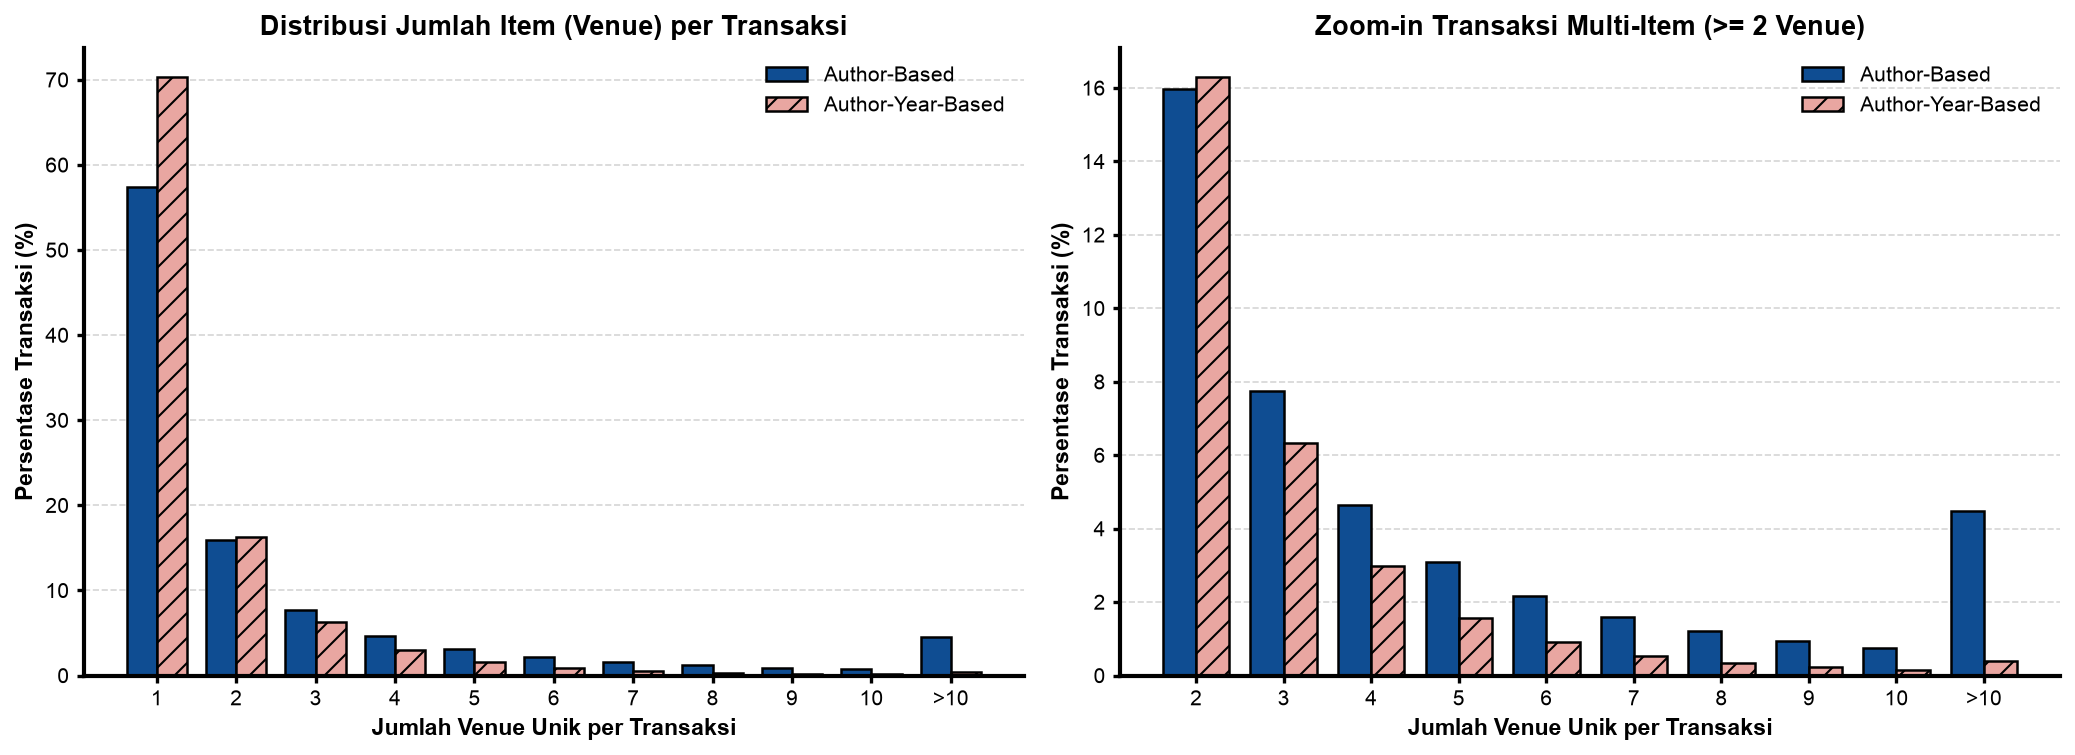

In [4]:
# Visualisasi perbandingan distribusi panjang transaksi (Author-Based vs Author-Year-Based)
buckets = dist_df[dist_df["representation"] == "Author-Based"].sort_values("bucket_order")["item_count_bucket"].tolist()
a_pct = dist_df[dist_df["representation"] == "Author-Based"].sort_values("bucket_order")["percentage"].values
ay_pct = dist_df[dist_df["representation"] == "Author-Year-Based"].sort_values("bucket_order")["percentage"].values

x = np.arange(len(buckets))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Panel A: Full distribution (bucket 1..>10)
b1 = axes[0].bar(x - width/2, a_pct, width, label="Author-Based", color=PALETTE["blue_main"], edgecolor="black", linewidth=1.2)
b2 = axes[0].bar(x + width/2, ay_pct, width, label="Author-Year-Based", color=PALETTE["red_2"], edgecolor="black", linewidth=1.2, hatch="//")
axes[0].set_title("Distribusi Jumlah Item (Venue) per Transaksi")
axes[0].set_xlabel("Jumlah Venue Unik per Transaksi")
axes[0].set_ylabel("Persentase Transaksi (%)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(buckets)
axes[0].legend(loc="upper right")
clean_axes(axes[0], grid_axis="y")

# Panel B: Zoom-in multi-item transactions (2..>10)
x2 = np.arange(len(buckets) - 1)
axes[1].bar(x2 - width/2, a_pct[1:], width, label="Author-Based", color=PALETTE["blue_main"], edgecolor="black", linewidth=1.2)
axes[1].bar(x2 + width/2, ay_pct[1:], width, label="Author-Year-Based", color=PALETTE["red_2"], edgecolor="black", linewidth=1.2, hatch="//")
axes[1].set_title("Zoom-in Transaksi Multi-Item (>= 2 Venue)")
axes[1].set_xlabel("Jumlah Venue Unik per Transaksi")
axes[1].set_ylabel("Persentase Transaksi (%)")
axes[1].set_xticks(x2)
axes[1].set_xticklabels(buckets[1:])
axes[1].legend(loc="upper right")
clean_axes(axes[1], grid_axis="y")

save_figure(fig, "../outputs/figures/03_tx_length_distribution")
plt.show()


## 3. Analisis Perbedaan, Kelebihan, dan Keterbatasan Kedua Representasi

### Perbedaan Utama
1. **Granularitas & Jumlah Transaksi**: *Author-Year-Based* memecah riwayat publikasi seorang author ke per tahun sehingga jumlah transaksinya jauh lebih besar dibanding *Author-Based*, sementara jumlah item unik (`8,780` venue) tetap sama.
2. **Kepadatan (Sparsity) & Proporsi Multi-Item**: Pada *Author-Based*, seluruh publikasi seorang peneliti selama 11 tahun (2015–2025) digabung dalam satu keranjang (*basket*), sehingga proporsi transaksi multi-item (`n_items >= 2`) dan rata-rata panjang transaksi jauh lebih tinggi dibanding *Author-Year-Based* (di mana sebagian besar peneliti hanya menerbitkan di 1 konferensi pada satu tahun kalender).
3. **Makna Ko-okurensi**:
   - Pada *Author-Based*, kemunculan bersama `{A, B}` berarti **peneliti yang sama pernah memublikasikan di A dan B** dalam rentang kariernya (2015–2025) — mencerminkan kedekatan komunitas riset jangka panjang.
   - Pada *Author-Year-Based*, kemunculan bersama `{A, B}` berarti **peneliti memublikasikan di A dan B pada tahun yang sama** — mencerminkan kolaborasi/produktivitas intensif simultan dan sangat cocok untuk pelacakan dinamika temporal antarperiode.

### Kelebihan dan Keterbatasan untuk Frequent Pattern Mining

| Aspek | Author-Based Transaction | Author-Year-Based Transaction |
|---|---|---|
| **Kelebihan** | - Menangkap pola lintas-tahun (mis. konferensi biennial seperti ICCV & ECCV yang jatuh di tahun ganjil/genap).<br>- Proporsi multi-item lebih tinggi sehingga menghasilkan frequent itemsets & association rules yang lebih kaya pada threshold `min_support` yang sama. | - Mempertahankan dimensi waktu sehingga dapat digunakan untuk **Temporal Association Analysis**.<br>- Memisahkan peneliti aktif jangka pendek vs panjang serta menangkap pergeseran fokus riset per periode. |
| **Keterbatasan** | - Menghilangkan informasi temporal (tidak membedakan apakah paper di A dan B terbit bersamaan atau terpaut 10 tahun).<br>- Berpotensi mencampur pergeseran bidang riset seorang peneliti dalam satu transaksi. | - Sangat *sparse*: mayoritas transaksi hanya berisi 1 venue (`n_items == 1`), sehingga support itemset berukuran `>= 2` jauh lebih kecil.<br>- Tidak dapat menangkap hubungan konferensi biennial (seperti ICCV–ECCV) karena keduanya hampir selalu berlangsung pada tahun berbeda. |
